In [ ]:
# ================================
# 1. IMPORT LIBRARIES
# ================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import RandomizedSearchCV
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error
from xgboost import XGBRegressor

In [ ]:
# ================================
# 2. LOAD DATA
# ================================

df = pd.read_csv("/content/Groundwater India Data.csv")

print("Dataset shape:", df.shape)
display(df.head())

Dataset shape: (416952, 15)


,time_idx,station_id,datetime,target,rainfall,t kmnpnn]2m,t2m_max,t2m_min,month,latitude,longitude,wellDepth,wellAquiferType_encoded,State_encoded,District_encoded
0,0,CGWHYD0426,2023-07-14,-11.3050,0.02,30.62,36.39,24.98,7,14.9083,78.0083,31.0,0,0,0
1,1,CGWHYD0426,2023-07-15,-11.2775,4.11,30.44,36.97,25.01,7,14.9083,78.0083,31.0,0,0,0
2,2,CGWHYD0426,2023-07-16,-11.2675,0.09,29.04,34.03,24.77,7,14.9083,78.0083,31.0,0,0,0
3,3,CGWHYD0426,2023-07-17,-11.2775,2.32,30.10,36.50,24.52,7,14.9083,78.0083,31.0,0,0,0
4,4,CGWHYD0426,2023-07-18,-11.2800,0.95,29.03,34.79,24.82,7,14.9083,78.0083,31.0,0,0,0


In [ ]:
# ================================
# 3. CLEAN & FEATURE ENGINEER
# ================================

df = df.rename(columns={'t  kmnpnn]2m': 't2m_avg'})
df['datetime'] = pd.to_datetime(df['datetime'])
df = df.sort_values(['station_id', 'datetime']).reset_index(drop=True)

# clip extreme outlier readings (~299 stations have datum-shift errors)
q01, q99 = df['target'].quantile([0.01, 0.99])
df['target'] = df['target'].clip(q01, q99)

# lag + rolling features
df['prev_target'] = df.groupby('station_id')['target'].shift(1)
df['rolling_rainfall_3'] = df.groupby('station_id')['rainfall'].transform(lambda s: s.rolling(3, min_periods=1).mean())
df = df.dropna(subset=['prev_target']).reset_index(drop=True)

features = ['month', 'rainfall', 't2m_avg', 't2m_max', 't2m_min',
            'latitude', 'longitude', 'wellDepth', 'wellAquiferType_encoded',
            'State_encoded', 'District_encoded', 'prev_target', 'rolling_rainfall_3']

print("Rows after cleaning:", len(df))
display(df[features].head())

Rows after cleaning: 410512


,month,rainfall,t2m_avg,t2m_max,t2m_min,latitude,longitude,wellDepth,wellAquiferType_encoded,State_encoded,District_encoded,prev_target,rolling_rainfall_3
0,8,0.02,26.53,28.14,25.29,8.2486,77.3083,31.45,1,1,1,7.67,0.010000
1,11,8.15,27.39,28.62,26.24,8.2486,77.3083,31.45,1,1,1,7.80,2.723333
2,1,0.00,26.92,30.61,23.76,8.2486,77.3083,31.45,1,1,1,7.86,2.723333
3,5,0.02,29.37,30.73,28.34,8.2486,77.3083,31.45,1,1,1,7.84,2.723333
4,8,0.08,27.37,28.63,26.54,8.2486,77.3083,31.45,1,1,1,7.65,0.033333


In [ ]:
# ================================
# 4. TIME-BASED TRAIN/TEST SPLIT
# ================================

cutoff_date = df['datetime'].quantile(0.8, interpolation='nearest')
print("Train/test cutoff date:", cutoff_date)

train_df = df[df['datetime'] <= cutoff_date]
test_df = df[df['datetime'] > cutoff_date]

X_train, y_train = train_df[features], train_df['target']
X_test, y_test = test_df[features], test_df['target']

print(f"Train: {len(X_train)} rows   Test: {len(X_test)} rows")

Train/test cutoff date: 2024-03-12 00:00:00
Train: 328476 rows   Test: 82036 rows


In [ ]:
# ================================
# 5. BASELINE MODELS (before tuning)
# ================================

rf_base = RandomForestRegressor(n_estimators=100, max_depth=10, n_jobs=-1, random_state=42)
rf_base.fit(X_train, y_train)
rf_base_pred = rf_base.predict(X_test)
print(f"RF baseline  - R2: {r2_score(y_test, rf_base_pred):.3f}  RMSE: {np.sqrt(mean_squared_error(y_test, rf_base_pred)):.3f}")

xgb_base = XGBRegressor(n_estimators=150, max_depth=6, learning_rate=0.1, n_jobs=-1, random_state=42)
xgb_base.fit(X_train, y_train)
xgb_base_pred = xgb_base.predict(X_test)
print(f"XGB baseline - R2: {r2_score(y_test, xgb_base_pred):.3f}  RMSE: {np.sqrt(mean_squared_error(y_test, xgb_base_pred)):.3f}")

RF baseline  - R2: 0.990  RMSE: 1.661
XGB baseline - R2: 0.987  RMSE: 1.902


In [ ]:
# ================================
# 6. HYPERPARAMETER TUNING
# ================================

rf_param_grid = {
    'n_estimators': [100, 200, 300],
    'max_depth': [8, 10, 15, None],
    'min_samples_split': [2, 5, 10],
}
rf_search = RandomizedSearchCV(
    RandomForestRegressor(random_state=42, n_jobs=-1),
    rf_param_grid, n_iter=8, cv=3, scoring='r2', random_state=42, n_jobs=-1
)
rf_search.fit(X_train, y_train)
print("Best RF params:", rf_search.best_params_)

xgb_param_grid = {
    'n_estimators': [100, 150, 200],
    'max_depth': [4, 6, 8],
    'learning_rate': [0.05, 0.1, 0.2],
    'subsample': [0.8, 1.0],
}
xgb_search = RandomizedSearchCV(
    XGBRegressor(random_state=42, n_jobs=-1),
    xgb_param_grid, n_iter=8, cv=3, scoring='r2', random_state=42, n_jobs=-1
)
xgb_search.fit(X_train, y_train)
print("Best XGB params:", xgb_search.best_params_)

KeyboardInterrupt: 

Random Forest (baseline) - R2: 0.990  RMSE: 1.661  MAE: 0.467
XGBoost (baseline)       - R2: 0.987  RMSE: 1.902  MAE: 0.699

Final model: Random Forest


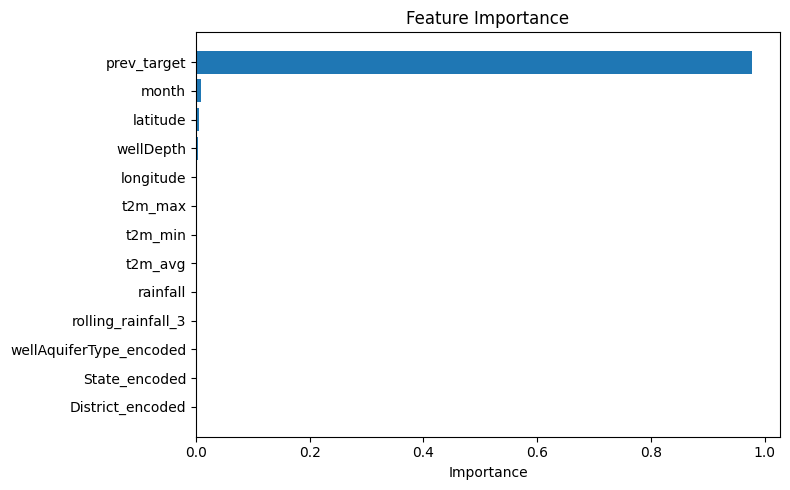

In [ ]:
# ================================
# 7. EVALUATE BASELINE MODELS (Fallback from Tuning)
# ================================

# Fallback to the already trained baseline models
rf_tuned = rf_base
xgb_tuned = xgb_base

rf_pred = rf_tuned.predict(X_test)
rf_r2 = r2_score(y_test, rf_pred)
print(f"Random Forest (baseline) - R2: {rf_r2:.3f}  RMSE: {np.sqrt(mean_squared_error(y_test, rf_pred)):.3f}  MAE: {mean_absolute_error(y_test, rf_pred):.3f}")

xgb_pred = xgb_tuned.predict(X_test)
xgb_r2 = r2_score(y_test, xgb_pred)
print(f"XGBoost (baseline)       - R2: {xgb_r2:.3f}  RMSE: {np.sqrt(mean_squared_error(y_test, xgb_pred)):.3f}  MAE: {mean_absolute_error(y_test, xgb_pred):.3f}")

model = xgb_tuned if xgb_r2 > rf_r2 else rf_tuned
print("\nFinal model:", "XGBoost" if model is xgb_tuned else "Random Forest")

importances = pd.Series(model.feature_importances_, index=features).sort_values(ascending=False)
plt.figure(figsize=(8, 5))
plt.barh(importances.index[::-1], importances.values[::-1])
plt.title("Feature Importance")
plt.xlabel("Importance")
plt.tight_layout()
plt.show()

In [ ]:
# ================================
# 8. RISK THRESHOLDS (direction-aware, with sparse-station flagging)
# ================================

MIN_READINGS_FOR_RELIABLE_THRESHOLD = 10

thresholds = {}
for station, grp in df.groupby('station_id'):
    vals = grp['target']
    # Some stations use the opposite sign convention (higher = more water).
    # Multiplying by sign puts every station on the same scale (higher = worse).
    sign = -1 if vals.median() < 0 else 1
    adj = vals * sign
    thresholds[station] = {
        'safe_max': adj.quantile(0.5),
        'declining_max': adj.quantile(0.8),
        'sign': sign,
        'n_readings': len(vals),
        'reliable': len(vals) >= MIN_READINGS_FOR_RELIABLE_THRESHOLD,
    }

n_unreliable = sum(1 for t in thresholds.values() if not t['reliable'])
n_flipped = sum(1 for t in thresholds.values() if t['sign'] == -1)
print(f"Computed thresholds for {len(thresholds)} stations")
print(f"Flagged as unreliable (<{MIN_READINGS_FOR_RELIABLE_THRESHOLD} readings): {n_unreliable}")
print(f"Stations using the opposite sign convention: {n_flipped}")

Computed thresholds for 6108 stations
Flagged as unreliable (<10 readings): 812
Stations using the opposite sign convention: 898


In [ ]:
# ================================
# 9. PREDICT FOR ALL STATIONS (direction-aware)
# ================================

latest = df.sort_values('datetime').groupby('station_id').tail(1).copy()
X_all = latest[features]
latest['predicted_level'] = model.predict(X_all)

def classify_risk(row):
    th = thresholds[row['station_id']]
    v = row['predicted_level'] * th['sign']   # same scale as the thresholds
    if v <= th['safe_max']:
        return 'Safe'
    elif v <= th['declining_max']:
        return 'Declining'
    else:
        return 'Critical'

latest['risk'] = latest.apply(classify_risk, axis=1)

print(f"Generated predictions for {len(latest)} stations")
print(latest['risk'].value_counts().to_dict())

chk = latest[latest['station_id'] == 'CGWB1ODKRD047'].iloc[0]
print(f"CGWB1ODKRD047 -> predicted {chk['predicted_level']:.2f}, risk {chk['risk']}")

Generated predictions for 6108 stations
{'Safe': 2755, 'Critical': 1697, 'Declining': 1656}
CGWB1ODKRD047 -> predicted -19.83, risk Safe


Station: CGWB1ODKRD047  (438 readings, reliable=True, sign=-1)
Predicted level: -19.83   Risk: Safe


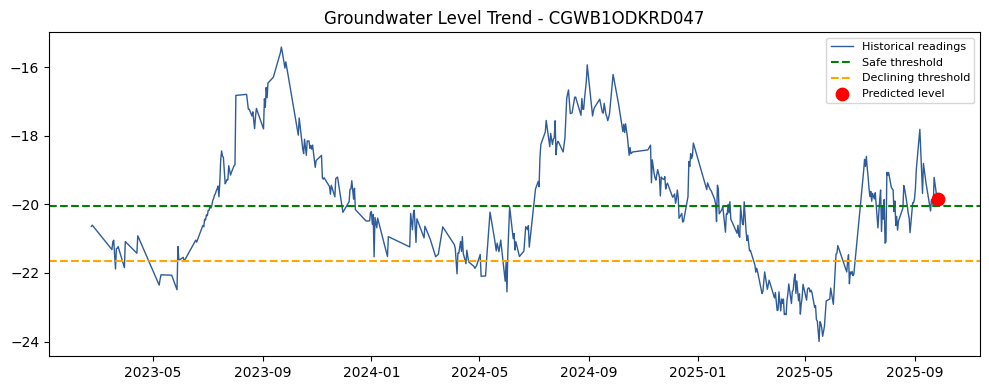

Station: CGWBHU2374  (415 readings, reliable=True, sign=-1)
Predicted level: -35.64   Risk: Safe


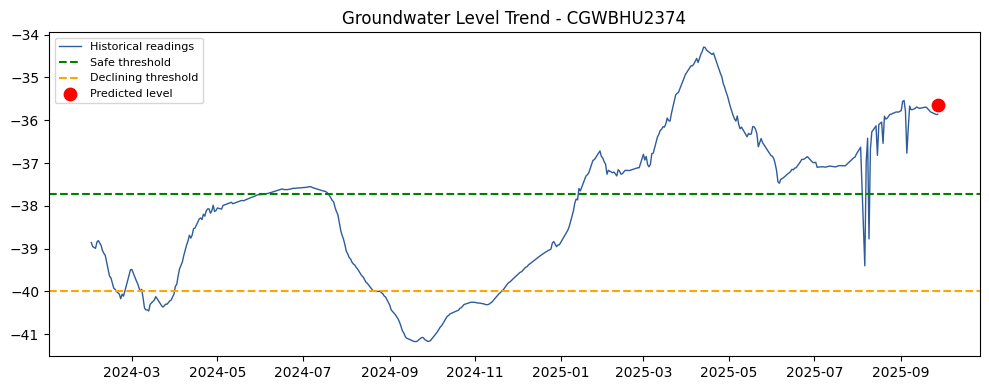

Station: CGWBNG0549  (408 readings, reliable=True, sign=-1)
Predicted level: -5.46   Risk: Declining


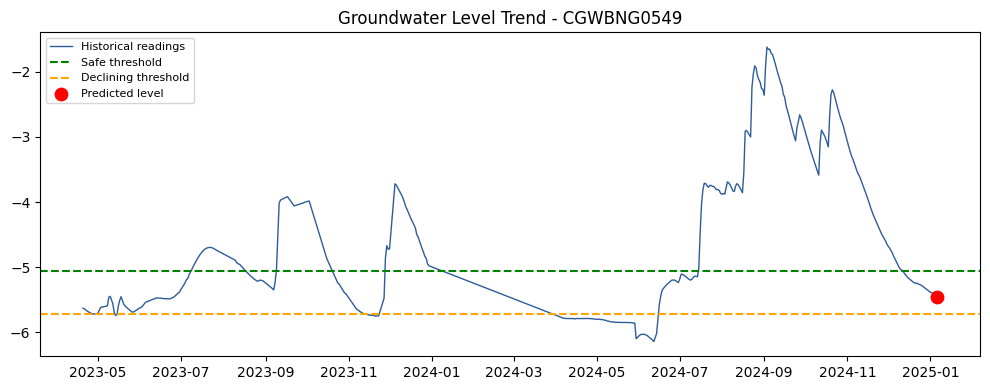

Station: CGWBNG0607  (429 readings, reliable=True, sign=-1)
Predicted level: -5.74   Risk: Critical


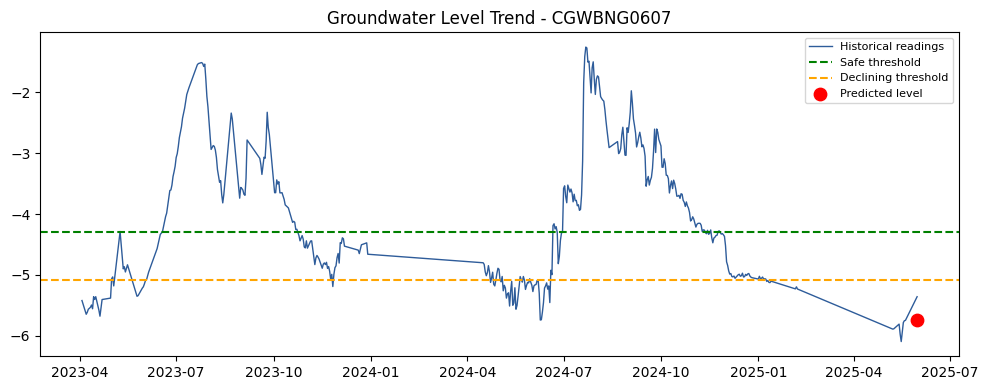

In [ ]:
# ================================
# 10. TREND CHART FUNCTION + SAMPLE STATIONS (direction-aware)
# ================================

def plot_station_trend(station_id, save_as=None):
    station_hist = df[df['station_id'] == station_id].sort_values('datetime')
    row = latest[latest['station_id'] == station_id].iloc[0]
    th = thresholds[station_id]

    print(f"Station: {station_id}  ({len(station_hist)} readings, reliable={th['reliable']}, sign={th['sign']})")
    print(f"Predicted level: {row['predicted_level']:.2f}   Risk: {row['risk']}")

    plt.figure(figsize=(10, 4))
    plt.plot(station_hist['datetime'], station_hist['target'], color='#2E5C9A', linewidth=1, label='Historical readings')
    plt.axhline(th['safe_max'] * th['sign'], color='green', linestyle='--', label='Safe threshold')
    plt.axhline(th['declining_max'] * th['sign'], color='orange', linestyle='--', label='Declining threshold')
    plt.scatter([station_hist['datetime'].iloc[-1]], [row['predicted_level']], color='red', s=80, zorder=5, label='Predicted level')
    plt.title(f"Groundwater Level Trend - {station_id}")
    plt.legend(fontsize=8)
    plt.tight_layout()
    if save_as:
        plt.savefig(save_as, dpi=300, bbox_inches='tight')
    plt.show()

# Fig. 2 station first (saved), then one busy station per risk class
plot_station_trend('CGWB1ODKRD047', save_as='fig2_trend.png')

station_counts = df['station_id'].value_counts()
for risk_level in ['Safe', 'Declining', 'Critical']:
    cand = latest[(latest['risk'] == risk_level) & (latest['station_id'] != 'CGWB1ODKRD047')]
    cand = cand.merge(station_counts.rename('n'), left_on='station_id', right_index=True).sort_values('n', ascending=False)
    if len(cand) > 0:
        plot_station_trend(cand.iloc[0]['station_id'])

{'Safe': 3134, 'Declining': 1480, 'Critical': 1494}


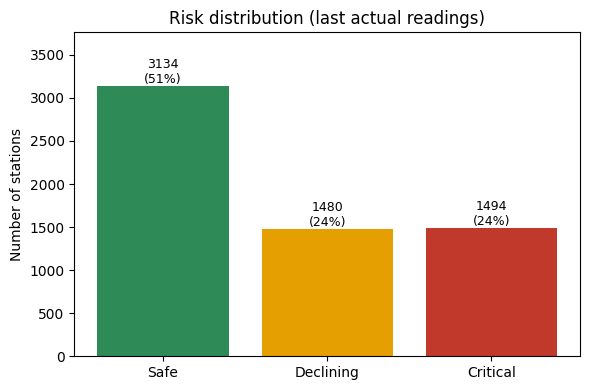

In [ ]:
# ================================
# 11. RISK DISTRIBUTION FROM LAST ACTUAL READINGS (direction-aware)
# ================================

def classify_actual(row):
    th = thresholds[row['station_id']]
    v = row['target'] * th['sign']
    if v <= th['safe_max']:
        return 'Safe'
    elif v <= th['declining_max']:
        return 'Declining'
    return 'Critical'

latest['actual_risk'] = latest.apply(classify_actual, axis=1)
counts = latest['actual_risk'].value_counts().reindex(['Safe', 'Declining', 'Critical'])
print(counts.to_dict())

total = counts.sum()
plt.figure(figsize=(6, 4))
bars = plt.bar(counts.index, counts.values, color=['#2E8B57', '#E69F00', '#C0392B'])
for b, c in zip(bars, counts.values):
    plt.text(b.get_x() + b.get_width() / 2, c, f"{c}\n({100*c/total:.0f}%)", ha='center', va='bottom', fontsize=9)
plt.ylabel('Number of stations')
plt.title('Risk distribution (last actual readings)')
plt.ylim(0, counts.max() * 1.2)
plt.tight_layout()
plt.savefig('risk_distribution.png', dpi=300, bbox_inches='tight')
plt.show()

In [ ]:
# ================================
# 12. INTERACTIVE PREDICTION (direction-aware)
# ================================

def predict_for_region(station_id, month=None, rainfall=None, t2m_avg=None, t2m_max=None, t2m_min=None):
    row = latest[latest['station_id'] == station_id]
    if len(row) == 0:
        print(f"Station '{station_id}' not found. Try one of: {list(latest['station_id'].sample(5))}")
        return

    row = row.iloc[0]
    th = thresholds[station_id]

    X_input = pd.DataFrame([{
        'month': month if month is not None else row['month'],
        'rainfall': rainfall if rainfall is not None else row['rainfall'],
        't2m_avg': t2m_avg if t2m_avg is not None else row['t2m_avg'],
        't2m_max': t2m_max if t2m_max is not None else row['t2m_max'],
        't2m_min': t2m_min if t2m_min is not None else row['t2m_min'],
        'latitude': row['latitude'], 'longitude': row['longitude'], 'wellDepth': row['wellDepth'],
        'wellAquiferType_encoded': row['wellAquiferType_encoded'],
        'State_encoded': row['State_encoded'], 'District_encoded': row['District_encoded'],
        'prev_target': row['target'],   # the station's latest actual reading
        'rolling_rainfall_3': row['rolling_rainfall_3'],
    }])[features]

    pred = model.predict(X_input)[0]
    v = pred * th['sign']
    risk = "Safe" if v <= th['safe_max'] else ("Declining" if v <= th['declining_max'] else "Critical")

    print(f"Region/Station: {station_id}")
    print(f"Input conditions -> month={X_input['month'].iloc[0]}, rainfall={X_input['rainfall'].iloc[0]:.1f}mm, "
          f"avg temp={X_input['t2m_avg'].iloc[0]:.1f}C")
    print(f"Predicted groundwater level: {pred:.2f}")
    print(f"Risk Classification: {risk}")
    if not th['reliable']:
        print("Note: this station has few historical readings, so the risk threshold may be less reliable.")
    return pred, risk

In [ ]:
predict_for_region("CGWB1ODKRD047")
predict_for_region("292415076392002")

Region/Station: CGWB1ODKRD047
Input conditions -> month=9, rainfall=15.5mm, avg temp=27.2C
Predicted groundwater level: -19.97
Risk Classification: Safe
Region/Station: 292415076392002
Input conditions -> month=10, rainfall=0.0mm, avg temp=26.1C
Predicted groundwater level: 21.00
Risk Classification: Critical


(np.float64(20.998186395792672), 'Critical')

In [ ]:
# ================================
# 14. PERSISTENCE BASELINE (predict = previous reading)
# ================================

persist = X_test['prev_target']
print(f"Persistence - R2: {r2_score(y_test, persist):.3f}  "
      f"RMSE: {np.sqrt(mean_squared_error(y_test, persist)):.3f}  "
      f"MAE: {mean_absolute_error(y_test, persist):.3f}")
print("Stations in test set:", test_df['station_id'].nunique())

Persistence - R2: 0.992  RMSE: 1.500  MAE: 0.299
Stations in test set: 563


In [ ]:
%%writefile app.py
import os
import numpy as np
import pandas as pd
import streamlit as st
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestRegressor

st.set_page_config(page_title="AI-Enabled Water Well Predictor", layout="wide")

CSV_CANDIDATES = ["/content/Groundwater India Data.csv", "Groundwater India Data.csv"]
FEATURES = ['month', 'rainfall', 't2m_avg', 't2m_max', 't2m_min',
            'latitude', 'longitude', 'wellDepth', 'wellAquiferType_encoded',
            'State_encoded', 'District_encoded', 'prev_target', 'rolling_rainfall_3']
MIN_READINGS = 10


def find_csv():
    for p in CSV_CANDIDATES:
        if os.path.exists(p):
            return p
    return None


def classify(value, th):
    v = value * th['sign']          # same scale as the thresholds (higher = worse)
    if v <= th['safe_max']:
        return 'Safe'
    elif v <= th['declining_max']:
        return 'Declining'
    return 'Critical'


@st.cache_resource(show_spinner="Loading data and training the model (first run takes a few minutes)...")
def build(csv_path):
    df = pd.read_csv(csv_path, dtype={'station_id': str})
    df = df.rename(columns={'t  kmnpnn]2m': 't2m_avg'})
    df['datetime'] = pd.to_datetime(df['datetime'])
    df = df.sort_values(['station_id', 'datetime']).reset_index(drop=True)

    q01, q99 = df['target'].quantile([0.01, 0.99])
    df['target'] = df['target'].clip(q01, q99)

    df['prev_target'] = df.groupby('station_id')['target'].shift(1)
    df['rolling_rainfall_3'] = df.groupby('station_id')['rainfall'].transform(
        lambda s: s.rolling(3, min_periods=1).mean())
    df = df.dropna(subset=['prev_target']).reset_index(drop=True)

    cutoff = df['datetime'].quantile(0.8, interpolation='nearest')
    train = df[df['datetime'] <= cutoff]
    model = RandomForestRegressor(n_estimators=100, max_depth=10, n_jobs=-1, random_state=42)
    model.fit(train[FEATURES], train['target'])

    thresholds = {}
    for station, grp in df.groupby('station_id'):
        vals = grp['target']
        sign = -1 if vals.median() < 0 else 1
        adj = vals * sign
        thresholds[station] = {
            'safe_max': adj.quantile(0.5),
            'declining_max': adj.quantile(0.8),
            'sign': sign,
            'n_readings': len(vals),
            'reliable': len(vals) >= MIN_READINGS,
        }

    latest = df.sort_values('datetime').groupby('station_id').tail(1).set_index('station_id')
    latest['actual_risk'] = [classify(r['target'], thresholds[s]) for s, r in latest.iterrows()]
    history = df[['station_id', 'datetime', 'target']]
    return model, thresholds, latest, history, cutoff


# ---------------- UI ----------------
st.title("AI-Enabled Water Well Predictor")
st.caption("Predicts the next groundwater reading for a monitoring station and classifies its risk "
           "(Safe / Declining / Critical) against that station's own history.")

csv_path = find_csv()
if csv_path is None:
    st.error("Could not find 'Groundwater India Data.csv'. Place it next to app.py (or in /content on Colab).")
    st.stop()

model, thresholds, latest, history, cutoff = build(csv_path)

tab_pred, tab_over = st.tabs(["Station prediction", "Risk overview"])

with tab_pred:
    stations = sorted(latest.index.tolist())
    default_idx = stations.index('CGWB1ODKRD047') if 'CGWB1ODKRD047' in stations else 0
    station = st.sidebar.selectbox("Station (type to search)", stations, index=default_idx)
    row = latest.loc[station]
    th = thresholds[station]

    st.sidebar.markdown("### Conditions (what-if)")
    month = st.sidebar.slider("Month", 1, 12, int(row['month']), key=f"m_{station}")
    rainfall = st.sidebar.number_input("Rainfall (mm)", min_value=0.0, value=float(row['rainfall']),
                                       step=1.0, key=f"r_{station}")
    t_avg = st.sidebar.number_input("Avg temperature (C)", value=float(row['t2m_avg']),
                                    step=0.5, key=f"ta_{station}")
    t_max = st.sidebar.number_input("Max temperature (C)", value=float(row['t2m_max']),
                                    step=0.5, key=f"tx_{station}")
    t_min = st.sidebar.number_input("Min temperature (C)", value=float(row['t2m_min']),
                                    step=0.5, key=f"tn_{station}")

    X = pd.DataFrame([{
        'month': month, 'rainfall': rainfall,
        't2m_avg': t_avg, 't2m_max': t_max, 't2m_min': t_min,
        'latitude': row['latitude'], 'longitude': row['longitude'], 'wellDepth': row['wellDepth'],
        'wellAquiferType_encoded': row['wellAquiferType_encoded'],
        'State_encoded': row['State_encoded'], 'District_encoded': row['District_encoded'],
        'prev_target': row['target'],              # the station's latest actual reading
        'rolling_rainfall_3': row['rolling_rainfall_3'],
    }])[FEATURES]
    pred = float(model.predict(X)[0])
    risk = classify(pred, th)

    c1, c2, c3 = st.columns(3)
    c1.metric("Predicted next level", f"{pred:.2f}")
    c2.metric("Last recorded level", f"{row['target']:.2f}")
    c3.metric("Readings on record", f"{th['n_readings']}")

    if risk == 'Safe':
        st.success(f"Risk classification: {risk}")
    elif risk == 'Declining':
        st.warning(f"Risk classification: {risk}")
    else:
        st.error(f"Risk classification: {risk}")

    if th['sign'] == -1:
        st.info("This station reports levels with the opposite sign convention "
                "(a higher value means more water), so thresholds are applied direction-aware.")
    if not th['reliable']:
        st.warning("This station has fewer than 10 readings, so its risk thresholds may be unreliable.")

    h = history[history['station_id'] == station].sort_values('datetime')
    fig, ax = plt.subplots(figsize=(10, 4))
    ax.plot(h['datetime'], h['target'], color='#2E5C9A', linewidth=1, label='Historical readings')
    ax.axhline(th['safe_max'] * th['sign'], color='green', linestyle='--', label='Safe threshold')
    ax.axhline(th['declining_max'] * th['sign'], color='orange', linestyle='--', label='Declining threshold')
    ax.scatter([h['datetime'].iloc[-1]], [pred], color='red', s=80, zorder=5, label='Predicted level')
    ax.set_title(f"Groundwater level trend - {station}")
    ax.legend(fontsize=8)
    fig.tight_layout()
    st.pyplot(fig)

    with st.expander("About this prediction"):
        st.write(
            "The model is a Random Forest trained on readings up to "
            f"{cutoff.date()}. It predicts the next reading from the station's latest reading, "
            "weather inputs and well attributes. The latest reading is the dominant input, and on "
            "next-reading prediction a simple persistence baseline (next = last) is slightly more "
            "accurate overall, so treat the output as an indicator, not a precise forecast.")

with tab_over:
    counts = latest['actual_risk'].value_counts().reindex(['Safe', 'Declining', 'Critical']).fillna(0).astype(int)
    total = int(counts.sum())
    fig2, ax2 = plt.subplots(figsize=(6, 4))
    bars = ax2.bar(counts.index, counts.values, color=['#2E8B57', '#E69F00', '#C0392B'])
    for b, c in zip(bars, counts.values):
        ax2.text(b.get_x() + b.get_width() / 2, c, f"{c}\n({100 * c / total:.0f}%)",
                 ha='center', va='bottom', fontsize=9)
    ax2.set_ylabel('Number of stations')
    ax2.set_title('Risk distribution (last actual readings)')
    ax2.set_ylim(0, counts.max() * 1.2)
    fig2.tight_layout()
    st.pyplot(fig2)
    st.caption(f"{total} stations. Thresholds are per station: Safe up to the median, "
               "Declining up to the 80th percentile, Critical above (direction-aware).")

Writing app.py


In [ ]:
# ================================
# STREAMLIT IN COLAB (Cloudflare tunnel)
# ================================
import subprocess, time, re, os

!pip install -q streamlit

# stop any earlier instance
!pkill -f streamlit || true
!pkill -f cloudflared || true

# start the app in the background
subprocess.Popen(
    ["streamlit", "run", "app.py", "--server.port", "8501",
     "--server.headless", "true", "--server.enableCORS", "false",
     "--server.enableXsrfProtection", "false"],
    stdout=open("streamlit.log", "w"), stderr=subprocess.STDOUT)

# get cloudflared and open the tunnel
if not os.path.exists("cloudflared"):
    !wget -q https://github.com/cloudflare/cloudflared/releases/latest/download/cloudflared-linux-amd64 -O cloudflared
    !chmod +x cloudflared

tunnel = subprocess.Popen(
    ["./cloudflared", "tunnel", "--url", "http://localhost:8501", "--no-autoupdate"],
    stdout=open("tunnel.log", "w"), stderr=subprocess.STDOUT)

url = None
for _ in range(40):
    time.sleep(1)
    m = re.search(r"https://[a-z0-9-]+\.trycloudflare\.com", open("tunnel.log").read())
    if m:
        url = m.group(0)
        break
print("Open this link:", url)
print("(First load trains the model, so allow a few minutes before the page appears.)")

^C
^C
Open this link: https://expiration-gap-amp-bloom.trycloudflare.com
(First load trains the model, so allow a few minutes before the page appears.)
